Leonez_Teresa_HW2

Name: Teresa Leonez

USC ID: tlee6409

## 1. Combined Cycle Power Plant Data Set

### (a) Download Data

Package imports

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [2]:
# Set up variables
RESPONSE = "PE"
FEATURES = {
    "AT": "Temperature",
    "V":  "Exhaust Vacuum",
    "AP": "Ambient Pressure",
    "RH": "Relative Humidity",
}
ALPHA = 0.05

Get the Cycle Power Plant Data Set

In [3]:
# Load file
file_name = "~/Dev/Class/DSCI 552/HW 2/CCPP/Folds5x2_pp.xlsx"

# Assign file data to dataframe
df = pd.read_excel(file_name, sheet_name=0, header=0)

### (b) Exploring the data

#### i. rows and columns

In [4]:
# Print the rows and columns in dataframe
answer = df.shape

print("There are ", 
      answer[0], "rows and",
      answer[1], "columns"
     )

# Labels the features in column headers
features_dict = {"AT": "Temperature", 
                 "AP": "Ambient Pressure", 
                 "RH": "Relative Humidity", 
                 "V": "Exhaust Vacuum"
                }

# Labels the predicted value in column headers
predict_dict = {"PE": "Energy Output"}

print("These columns represent the features:")
for key, value in features_dict.items():
    print(key, value)

print("The last column represents the output:")
print(predict_dict)

print("Each row represents a data point, one hour of data at the plant, and the hourly average of the 4 conditions listed plus the energy output")

There are  9568 rows and 5 columns
These columns represent the features:
AT Temperature
AP Ambient Pressure
RH Relative Humidity
V Exhaust Vacuum
The last column represents the output:
{'PE': 'Energy Output'}
Each row represents a data point, one hour of data at the plant, and the hourly average of the 4 conditions listed plus the energy output


#### ii. pairwise scatterplots of all the varianbles

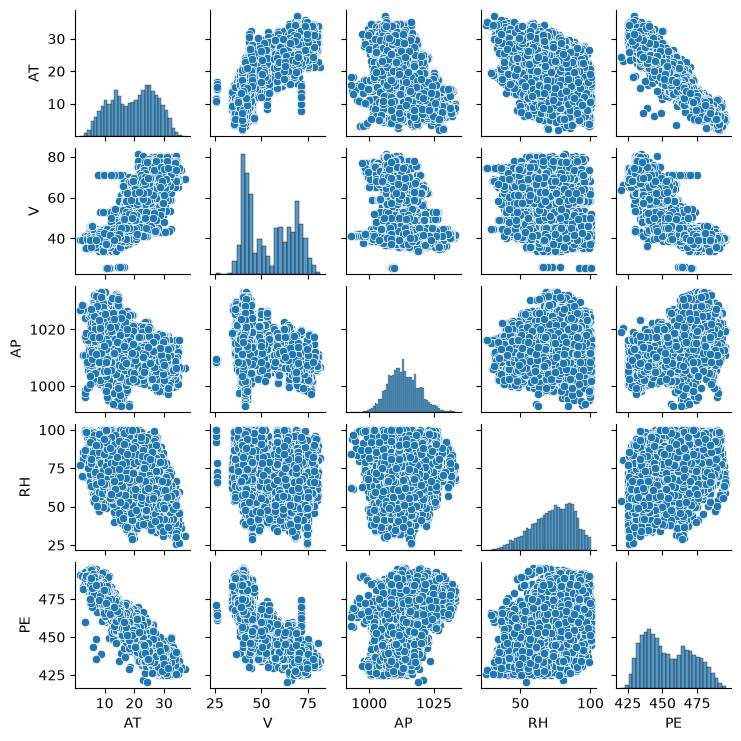

In [48]:
# Generate the pairwise scatterplot matrix
sns.pairplot(df, height=1.5)

Text(0.5, 1.2, 'Scatterplot of features vs energy output')

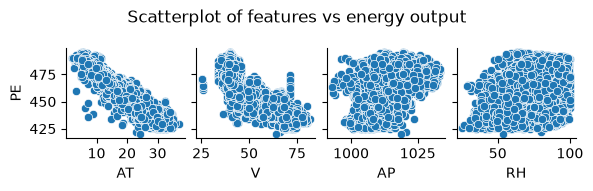

In [5]:
# Pairplot of just the features with the predicted output
g = sns.pairplot(df, x_vars=["AT", "V", "AP", "RH"], y_vars=["PE"], height=1.5)
g.fig.suptitle("Scatterplot of features vs energy output", y=1.2)

1)ii. Based on the scatterplots, there appears to be a strong negative correlation between ambient temperature and energy output. The higher the average hourly temperature recorded, the lower the energy output. The exhaust vaccum also has a high negative impact on the energy output, though at less present of a corrleation. Neitehr Ambient pressure nor Relative humidity have appear to have a strong correlation to the energy output.  The scatterplots also show that vaccum and ambient temperature appear to be correlated as well.

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

In [6]:
# Get the stats for the dataset
stats = df.describe()
stats.loc["range"] = stats.loc["max"]-stats.loc["min"] # Get range
stats.loc["IQR"] = stats.loc["75%"]-stats.loc["25%"] # Get IQR

print(stats.round(2))

            AT        V       AP       RH       PE
count  9568.00  9568.00  9568.00  9568.00  9568.00
mean     19.65    54.31  1013.26    73.31   454.37
std       7.45    12.71     5.94    14.60    17.07
min       1.81    25.36   992.89    25.56   420.26
25%      13.51    41.74  1009.10    63.33   439.75
50%      20.34    52.08  1012.94    74.97   451.55
75%      25.72    66.54  1017.26    84.83   468.43
max      37.11    81.56  1033.30   100.16   495.76
range    35.30    56.20    40.41    74.60    75.50
IQR      12.21    24.80     8.16    21.50    28.68


### (c) Simple Linear Regression

In [7]:
# For each predictor fit a simple linear regression model

def fit_linear_regression(df,x,y):   # Create repeatable function to make linear regression
    model = smf.ols(f"{y} ~ {x}", data=df).fit()
    return model

def plot_scatter_fit(df, x, y, ax, label):   # Create a scatterplot and fitted regression line from data
    sns.regplot(x=x, y=y, data=df, ax=ax,
                scatter_kws={"s": 3, "alpha": 0.3},
                line_kws={"color": "red"})
    ax.set_title(f"{y} vs {label}")

def plot_residuals(model, ax, label):   # Create a residual plot with outliers labeled
    ax.scatter(model.fittedvalues, model.resid, s=3, alpha=0.3)
    ax.axhline(0, color="red")
    ax.set(title=f"Residuals: {label}", xlabel="Fitted", ylabel="Residual")
    

In [8]:
results_dict = {}  # Create dictionary to store key stats for each variable
linreg_models = {} # Create dictionary to store linear regression models

for feature, label in FEATURES.items():  # Find the linear regression model for each dependent variable
    print(f"Energy Output as predicted by {label}")
    model = fit_linear_regression(df, feature, RESPONSE)   # Call linear regression function
    linreg_models[feature] = model

    intercept = model.params["Intercept"]  # Find model intercept
    slope = model.params[feature]  # Find model slope
    print(f"{label}: {RESPONSE} = {slope:.2f} * {feature} + {intercept:.2f}")  # Print model as line rounded to 2 decimals for quick comprehension

    # Pull key model parameters into results dictionary for storage
    results_dict[feature] = {   
        "intercept": model.params["Intercept"],
        "slope": model.params[feature], # Inner dictionary stores features stats
        "p_value": model.pvalues[feature],
        "r_squared": model.rsquared,
    }

Energy Output as predicted by Temperature
Temperature: PE = -2.17 * AT + 497.03
Energy Output as predicted by Exhaust Vacuum
Exhaust Vacuum: PE = -1.17 * V + 517.80
Energy Output as predicted by Ambient Pressure
Ambient Pressure: PE = 1.49 * AP + -1055.26
Energy Output as predicted by Relative Humidity
Relative Humidity: PE = 0.46 * RH + 420.96


In [9]:
# Convert results into table for easier reading
results_df = pd.DataFrame(results_dict).T 
print(results_df.round(4))

    intercept   slope  p_value  r_squared
AT   497.0341 -2.1713      0.0     0.8989
V    517.8015 -1.1681      0.0     0.7565
AP -1055.2610  1.4899      0.0     0.2688
RH   420.9618  0.4557      0.0     0.1519


In [10]:
# Analyze results
def significant_pvalue_calc(alpha, df): # Find significant p values in a data frame
    results_list = df[df["p_value"] < alpha].index
    return list(results_list)

feature_names = [features_dict[f] for f in significant_pvalue_calc(.05, results_df)]
print(f"The features with significant p-values (with alpha as .05) are: {feature_names}")

maxr2_feature, max_r2 = results_df["r_squared"].idxmax(), results_df["r_squared"].max()   # Find the highest r2 value from all variables
print(f"The feature with the strongest correlation with energy output is {features_dict[maxr2_feature]} with r2 value of {max_r2:.2f}")


The features with significant p-values (with alpha as .05) are: ['Temperature', 'Exhaust Vacuum', 'Ambient Pressure', 'Relative Humidity']
The feature with the strongest correlation with energy output is Temperature with r2 value of 0.90


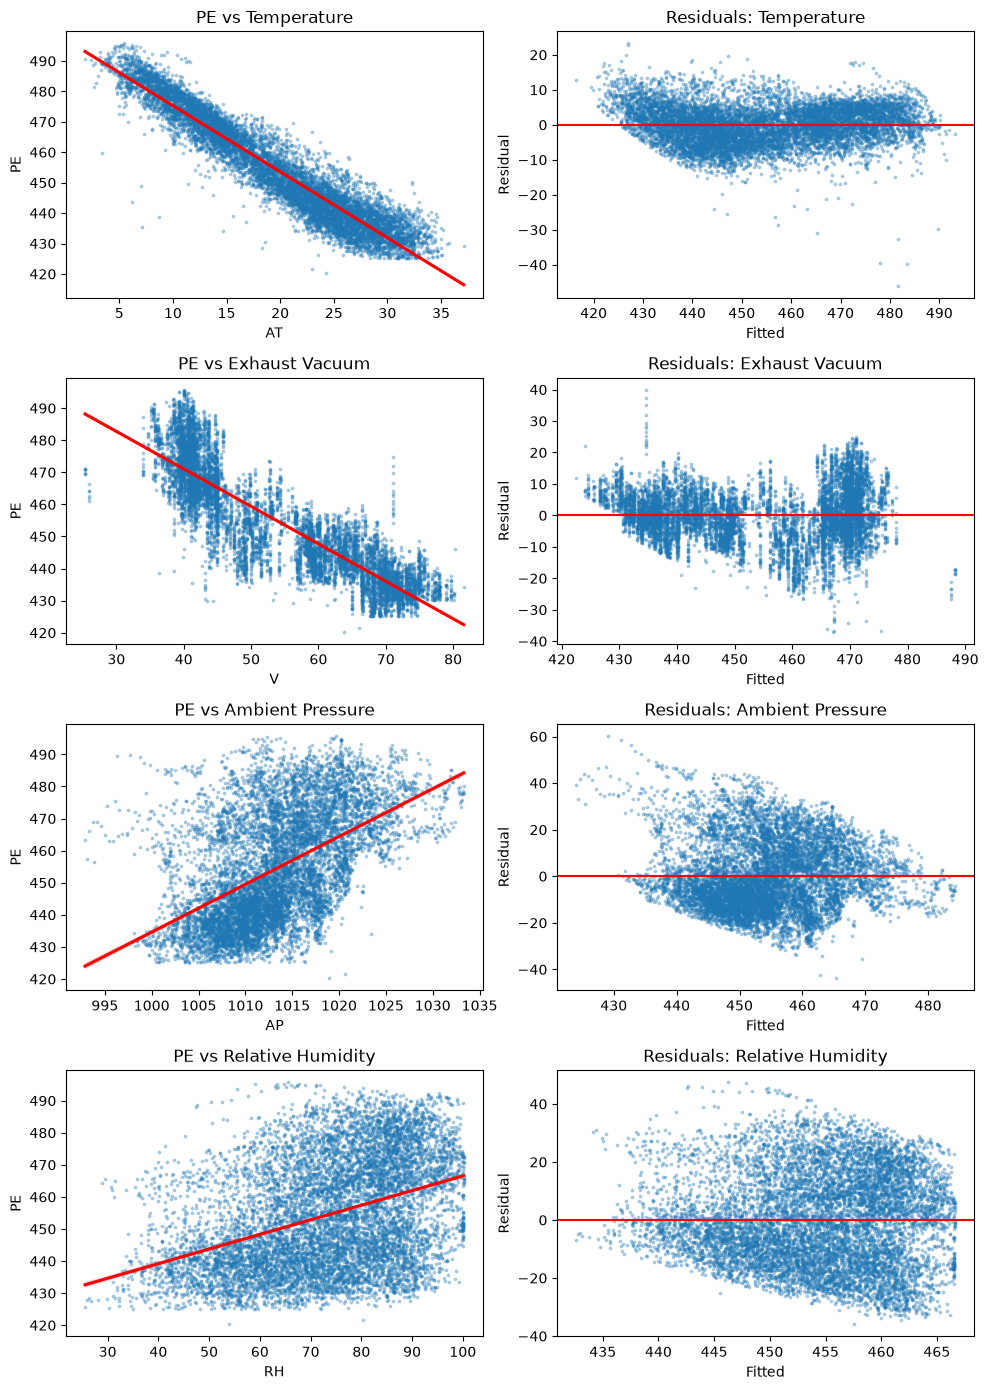

In [11]:
fig, axes = plt.subplots(len(FEATURES), 2, figsize=(10, 14))

for row, (feature, label) in enumerate(FEATURES.items()):
    plot_scatter_fit(df, feature, RESPONSE, axes[row, 0], label)
    plot_residuals(linreg_models[feature], axes[row, 1], label)

plt.tight_layout()
plt.show()

1.3.c Answer: based on the plots, the PE vs Vacuum and PE vs Temperature appear to have the highest correlations (Temp R2=.90, Vacuum R2 = .76). In the PE vs Temp plot, there are outliers but they are below the expected output on low temperature days, while we are not seeing many outliers that exceed output on high temperature days, possibly due to other confounding factors affecting low output.

All 4 variables produce significant values (p<.05) using .05 as the alpha. 

I would not remove the outliers based on this reading, they do not seem to have significant pull on the dataset, considering how large the dataset is.

### (d) Multiple Regression

In [12]:
# Fit multiple regression model
#h_null = 
#h_alt = 

# Combine features from simple regression to build multiple regression
joined_features = " + ".join(FEATURES)
multi_model = fit_linear_regression(df, joined_features, RESPONSE)
print(multi_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:06:09   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    454.6093      9.749     46.634      0.0

In [13]:
# map correlation between variables
correlation_table = df.corr().round(2)
print(correlation_table)

      AT     V    AP    RH    PE
AT  1.00  0.84 -0.51 -0.54 -0.95
V   0.84  1.00 -0.41 -0.31 -0.87
AP -0.51 -0.41  1.00  0.10  0.52
RH -0.54 -0.31  0.10  1.00  0.39
PE -0.95 -0.87  0.52  0.39  1.00


After running the multiple regression model with all 4 predicting variables, the highest t-statistic is AT, with a high negative coefficient, while the coefficient for Vacuum remained negative but went down (weighted less overall, accounting for the high correlation between Temp and Vacuum at .84), and the coefficient for Relative Humiditiy flipped to negative from being positive in the simple regression model, suggesting that it is correlated to another independent variable (correlated at -.54 to Temp and -.31 to Vaccum).  Given that the temperature affects the humidity, this suggests that once temperature variable's weight is accounted for, the effect of Relative Humidity becomes slightly negative.

For which predictors can we reject null?
Answer: Since all four variables have a p value lower than .05, we can reject the null hypothesis for all 4 variables: AT, V, AP, and RH.

### (e) 1c Compare to 1d

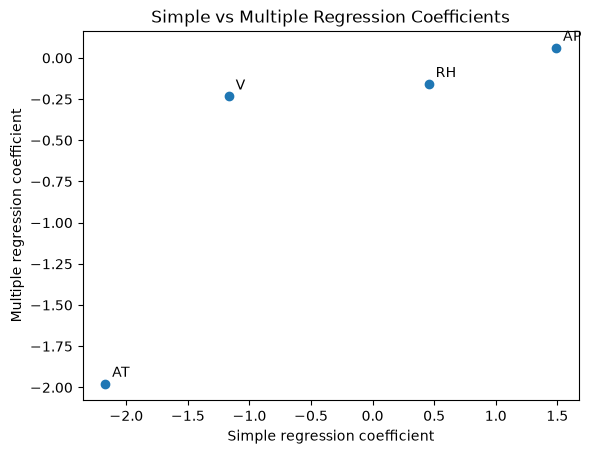

In [14]:
x_values = []  # creates list to store x data
y_values = [] # creates list to store y results

for feature in FEATURES:
    x_values.append(linreg_models[feature].params[feature]) # take univariate regression coefficient from 1c and append to x value list
    y_values.append(multi_model.params[feature])  # take multiple regression coeffient from 1d and append to the y value list


plt.scatter(x_values, y_values)  # Plot the values

for feature, x, y in zip(FEATURES, x_values, y_values):
    plt.annotate(feature, (x,y),  textcoords="offset points", xytext=(5, 5))

plt.xlabel("Simple regression coefficient")
plt.ylabel("Multiple regression coefficient")
plt.title("Simple vs Multiple Regression Coefficients")
plt.show()

### (f) Nonlinear Association

In [15]:
# fit model of the form to polynomial

poly = PolynomialFeatures(degree=3, include_bias=False)  # X, X2, X3 and skip the column of 1s
poly_models = {} # Creates dictionary to store the polynomial models

for feature, label in FEATURES.items():
    df_centered = df[[feature]] - df[feature].mean()   # Center the feature for large AP numbers
    X_poly = poly.fit_transform(df_centered)
    names = poly.get_feature_names_out([feature])         # get feature names ex. 'AT'
    X_poly = pd.DataFrame(X_poly, columns=names, index=df.index)
    X_poly = sm.add_constant(X_poly)                      # adds the intercept column

    model = sm.OLS(df[RESPONSE], X_poly).fit()
    poly_models[feature] = model

    print(f"\n{label}")
    print(model.pvalues.round(4))


Temperature
const    0.0
AT       0.0
AT^2     0.0
AT^3     0.0
dtype: float64

Exhaust Vacuum
const    0.0000
V        0.0000
V^2      0.0000
V^3      0.0137
dtype: float64

Ambient Pressure
const    0.0
AP       0.0
AP^2     0.0
AP^3     0.0
dtype: float64

Relative Humidity
const    0.0000
RH       0.0000
RH^2     0.1014
RH^3     0.0000
dtype: float64


Answer: Yes. All 4 variables show evidence of non-linear association.
Based on the polynomial models for each variable, there is evidence of a non-linear association for Temperature at the 2nd and 3rd degree, Exhaust Vacuum at 2nd and 3rd degree, Ambient Pressure at the 2nd and 3rd degree, and Relative Humidity at the 3rd degree, but not 2nd degree. These are based on p values being less than .05. Only RH at RH2 has a larger p-value at .1014.

### (g) Interactions of Predictors

In [16]:
# Build Pairwise interaction model 
formula_string = f"({' + '.join(FEATURES)})**2"

pairwise_model = fit_linear_regression(df, formula_string, RESPONSE)
pairwise_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:06:22   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.000     531.631     839.934
AT            -4.3470      2.373     -1.832      0.067      -8.999       0.305
V             -7.6749      1.351     -5.682      0.000     -10.323      -5.027
AP            -0.1524      0.077     -1.983      0.047      -0.303      -0.002
RH             1.5709      0.773      2.031      0.042       0.055       3.087
AT:V           0.0210      0.001     23.338      0.000       0.019       0.023
AT:AP          0.0018      0.002      0.752      0.452      -0.003       0.006
AT:RH         -0.0052      0.001     -6.444      0.000      -0.007      -0.004
V:AP           0.0068      0.001      5.135      0.000       0.004       0.009
V:RH           0.0008      0.000      1.716      0.086      -0.000       0.002
AP:RH         -0.0016      0.001     -2.125      0.034      -0.003      -0.000
==============================================================================
Omnibus:                     1454.609   Durbin-Watson:                   2.030
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9170.848
Skew:                          -0.574   Prob(JB):                         0.00
Kurtosis:                       7.657   Cond. No.                     1.70e+08
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.7e+08. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [17]:
pairwise_interactions = pairwise_model.pvalues.filter(like=":").round(4)
print(f"Pairwise Interaction p-values:\n {pairwise_interactions}")

Pairwise Interaction p-values:
 AT:V     0.0000
AT:AP    0.4521
AT:RH    0.0000
V:AP     0.0000
V:RH     0.0862
AP:RH    0.0336
dtype: float64


Answer: Yes, there is evidence of association (p < .05) for pairwise interactions between Tempeature and Vacuum, Temperature and Relative Humidity, Vacuum and Ambient Pressure, and Ambient Pressure and Relative Humidity.

### (h) Improvement

In [18]:
# Create function to get MSE for training and testing data for fitted model
def train_test_mse(model, train, test, response):  
    train_mse = mean_squared_error(train[response], model.predict(train))
    test_mse = mean_squared_error(test[response], model.predict(test))
    return train_mse, test_mse

# Split the data 30% test, 70% train, randomly
train, test = train_test_split(df, test_size=0.3, random_state=42)

In [19]:
# Fit the model as a basic linear model with the split training data
linear_model = fit_linear_regression(train, joined_features, RESPONSE)
linear_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 2.194e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:06:31   Log-Likelihood:                -19630.
No. Observations:                6697   AIC:                         3.927e+04
Df Residuals:                    6692   BIC:                         3.930e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    467.8414     11.502     40.673      0.000     445.293     490.390
AT            -2.0044      0.018   -110.340      0.000      -2.040      -1.969
V             -0.2271      0.009    -26.301      0.000      -0.244      -0.210
AP             0.0493      0.011      4.416      0.000       0.027       0.071
RH            -0.1600      0.005    -32.337      0.000      -0.170      -0.150
==============================================================================
Omnibus:                      703.168   Durbin-Watson:                   1.999
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3512.957
Skew:                          -0.390   Prob(JB):                         0.00
Kurtosis:                       6.461   Cond. No.                     2.11e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.11e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [21]:
# build the "improved" model by adding on the additional interactions
interactive_features = f"({joined_features})**2" # Adds pairwise interactions
quadratic_features = ' + '.join(f"I({f}**2)" for f in FEATURES) # Adds squared terms 
formula = f"{interactive_features} + {quadratic_features}" # Combines pairwise and squares

# Re train the model using the additional interactions
improved_model = fit_linear_regression(train, formula, RESPONSE)

In [22]:
# Find insignificant p-values
print(improved_model.pvalues[improved_model.pvalues > ALPHA])

# Compare the significant p-values
print(improved_model.pvalues[improved_model.pvalues < ALPHA].round(4))

V            0.267182
AT:AP        0.196631
V:AP         0.381180
V:RH         0.867382
I(V ** 2)    0.699802
dtype: float64
Intercept     0.0000
AT            0.0446
AP            0.0000
RH            0.0001
AT:V          0.0032
AT:RH         0.0031
AP:RH         0.0003
I(AT ** 2)    0.0000
I(AP ** 2)    0.0000
I(RH ** 2)    0.0000
dtype: float64


For the improved model, I dropped the variables ATxAP, VxAP, VxRH, V^2, but kept V even though it had a high p-value, because the correlated pair ATxV has a low p-value and the hierarchy rule keeps the singular variable if it's part of significant interaction.

In [23]:
# Drop the insignificant features and rerun the model

drop_features = ["AT:AP", "V:AP", "V:RH", "I(V ** 2)"]
keep_terms = [t for t in improved_model.params.index
              if t not in drop_features and t != "Intercept"]

pruned_formula = ' + '.join(keep_terms)
print(pruned_formula)

# Improved model without the insignificant terms
pruned_model = fit_linear_regression(train, pruned_formula, RESPONSE) 
pruned_model.summary()

AT + V + AP + RH + AT:V + AT:RH + AP:RH + I(AT ** 2) + I(AP ** 2) + I(RH ** 2)


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                 1.017e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:07:00   Log-Likelihood:                -19166.
No. Observations:                6697   AIC:                         3.835e+04
Df Residuals:                    6686   BIC:                         3.843e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.046e+04   1091.512     -9.581      0.000   -1.26e+04   -8317.797
AT            -2.4293      0.100    -24.221      0.000      -2.626      -2.233
V             -0.4542      0.032    -14.187      0.000      -0.517      -0.391
AP            21.1531      2.158      9.804      0.000      16.924      25.383
RH             5.6754      0.755      7.512      0.000       4.194       7.156
AT:V           0.0080      0.001      5.509      0.000       0.005       0.011
AT:RH         -0.0069      0.001     -7.937      0.000      -0.009      -0.005
AP:RH         -0.0053      0.001     -7.244      0.000      -0.007      -0.004
I(AT ** 2)     0.0170      0.002      7.478      0.000       0.013       0.021
I(AP ** 2)    -0.0102      0.001     -9.558      0.000      -0.012      -0.008
I(RH ** 2)    -0.0021      0.000     -7.638      0.000      -0.003      -0.002
==============================================================================
Omnibus:                     1192.150   Durbin-Watson:                   2.001
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             8095.922
Skew:                          -0.679   Prob(JB):                         0.00
Kurtosis:                       8.213   Cond. No.                     2.17e+10
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.17e+10. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [24]:
# Get MSE for training data and testing data on linear and improved model
train_mse_basic, test_mse_basic = train_test_mse(linear_model, train, test, RESPONSE)
train_mse_improved, test_mse_improved = train_test_mse(pruned_model, train, test, RESPONSE)
print(f"Linear\n Train MSE: {train_mse_basic:.2f}\n Test MSE: {test_mse_basic:.2f}")
print(f"Improved\n Train MSE: {train_mse_improved:.2f}\n Test MSE: {test_mse_improved:.2f}")

Linear
 Train MSE: 20.58
 Test MSE: 21.24
Improved
 Train MSE: 17.92
 Test MSE: 18.69


Answer: Yes, the model can be improved using all possible interaction terms and non-linear associations. The Testing Mean Squared Error goes from 21.24 in the linear model to 18.69 in the final pruned/improved model. (The training MSE goes from 20.58 down to 17.92)



### (i) KNN

In [28]:
# Use KNN on dataset
feature_cols = list(FEATURES)
X_train, X_test = train[feature_cols], test[feature_cols]
y_train, y_test = train[RESPONSE], test[RESPONSE]

# Create function for knn errors on train and test values
def knn_errors(X_train, X_test, y_train, y_test, k_values):
    train_errors = []
    test_errors = [] 
    
    for k in k_values:
        knn = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
        train_errors.append(mean_squared_error(y_train, knn.predict(X_train)))
        test_errors.append(mean_squared_error(y_test, knn.predict(X_test)))
    return train_errors, test_errors

# Normalized features
scaler = StandardScaler().fit(X_train)
X_train_norm, X_test_norm = scaler.transform(X_train), scaler.transform(X_test)

# Raw features
k_values = range(1, 101)
raw_train, raw_test = knn_errors(X_train, X_test, y_train, y_test, k_values)
norm_train, norm_test = knn_errors(X_train_norm, X_test_norm, y_train, y_test, k_values)

Raw: Best k = 5, Test MSE = 15.73
Normalized: Best k = 4, Test MSE = 14.31


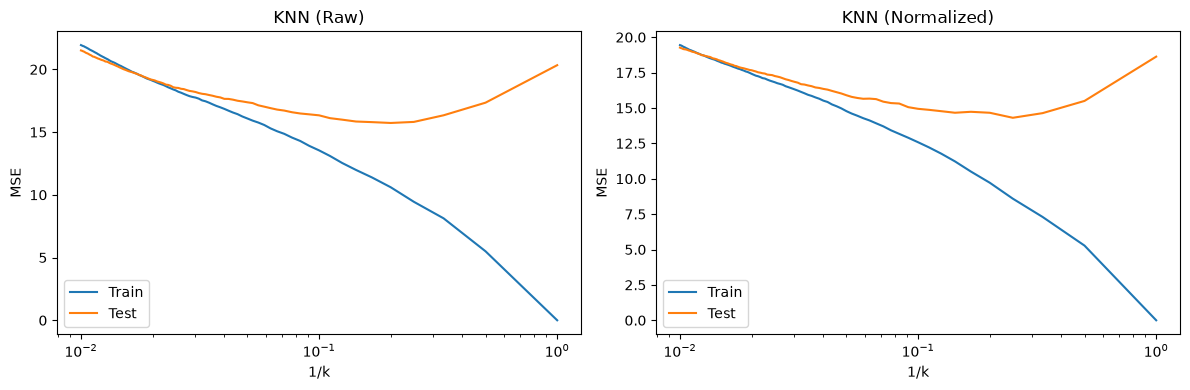

In [30]:
# Use lowest test error to determine the best k-value
best_raw = k_values[np.argmin(raw_test)]
best_norm = k_values[np.argmin(norm_test)]
print(f"Raw: Best k = {best_raw}, Test MSE = {min(raw_test):.2f}")
print(f"Normalized: Best k = {best_norm}, Test MSE = {min(norm_test):.2f}")

# Plot the train and test errors in terms of 1/k
inver_k = [1 / k for k in k_values]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (train, test, name) in zip(axes, [(raw_train, raw_test, "Raw"),
                                      (norm_train, norm_test, "Normalized")]):
    ax.plot(inver_k, train, label="Train")
    ax.plot(inver_k, test, label="Test")
    ax.set(xscale="log", xlabel="1/k", ylabel="MSE", title=f"KNN ({name})")
    ax.legend()
    
plt.tight_layout()
plt.show()

Answer: The best value for k from between 1-100 is 4 going off of the normalized data, and 5 going off of the raw data. The test error is 15.73 for raw data and 14.31 for normalized data. The normalized data is slightly lower MSE. In both models, as 1/k increases, the error curves, dips, and goes back up in a U shape at the best k-value (Raw data, k=5 and Normalized data, k =4). 

### (j ) Compare KNN and Linear

The lowest test error from the linear regression model was 18.69, using the "improved" model, while the KNN model had a test error of 14.31, indicating the KNN model may be a better fit. It is the more flexible model, while the linear model is more inflexible. Since the sample size is very large (n = 9568), with relatively low predictors (4), the more flexible model is better and can capture the wiggly pattern without overfitting. However, the linear model allows more details like p values and feature coefficient and interaction associations, while the KNN method is a blackbox. In the case of predicting more accurately, KNN is better. In the case of learning/extracting insights about features and their weighted effect on the predicted outcome, linear regression model is better here.

## 2. ISLR: 2.4.1

### (a) The sample size n is extremely large, and the number of predictors p is small.

We expect the flexible method to be better. In general, flexible methods have higher variance. With the bias variance trade-off, flexible methods require a lot more data or else it will risk over-fitting the model, resulting in high variance. The higher the variance, the lower the bias, and vice versa. Since this sample size is extremely large, we can benefit from the low bias without significant risk of high variance.

### (b) The number of predictors p is extremely large, and the number of observations n is small.

We expect the flexible method in this case to be worse. With an extremely small number of observations, we risk high variance. With the high p, the model also risks overfitting with trying to learn too many predictors with not enough data points for each.

### (c) The relationship between the predictors and response is highly non-linear.

We expect the flexible method to be better in this case. Flexible methods are better used for curved patterns since inflexible methods are straight-lines which results in high bias.

### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.

In this case the flexible method is worse, because the variance is high with lots of random noise, and the result would be a model trying to fit the changes too specifically, resulting in overfitting and higher variance.

## 3. ISLR: 2.4.7

### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

In [56]:
# Create observation matrix
observations = {
    1: (0, 3, 0, "Red"),
    2: (2, 0, 0, "Red"),
    3: (0, 1, 3, "Red"),
    4: (0, 1, 2, "Green"),
    5: (-1, 0, 1, "Green"),
    6: (1, 1, 1, "Red"),
}
TEST_POINT = (0, 0, 0)  # Given as test point

def euclidean_distance(point, test_point):  # Function to calculate the shortest straight line distnce between points
    distance = np.linalg.norm(np.array(point) - np.array(test_point))
    return distance
    
distances = {} # Empty dictionary to store distances
for obs, values in observations.items():
    distances[obs] = euclidean_distance(values[:3], TEST_POINT)   # Calculate distances between 6 observations to test point for x1, x2, x3
    print(f"Observation {obs}: {distances[obs].round(2)}")
    
for obs, dist in sorted(distances.items(), key=lambda item: item[1]):
    print(f"Obs {obs}: distance = {dist:.2f}, color = {observations[obs][3]}")

Observation 1: 3.0
Observation 2: 2.0
Observation 3: 3.16
Observation 4: 2.24
Observation 5: 1.41
Observation 6: 1.73
Obs 5: distance = 1.41, color = Green
Obs 6: distance = 1.73, color = Red
Obs 2: distance = 2.00, color = Red
Obs 4: distance = 2.24, color = Green
Obs 1: distance = 3.00, color = Red
Obs 3: distance = 3.16, color = Red


### (b) What is our prediction with K = 1? Why?

Using test point as 0,0,0 and KNN with K=1, the closest observation is Observation 5 at 1.41, predicting Green.

### (c) What is our prediction with K = 3? Why?

The closest neighbor 3 neighbors (K=3) are 5, 6, and 2. Out of those observations, there is 1 green and 2 red. Since red is the majority, we would predict Red.

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

Answer: A smaller K value would be better in this case because it uses a smaller number of nearest neighbors, allowing the resulting model to be more wiggly and flexible, over an inflexible boundary that would be closer to a linear model.